# Altitude PPO — fixed 5 m versus curriculum

Train two PPO agents from scratch for **1,500,000 environment steps each**:
one always targets 5 m, the other uses the existing curriculum ladder.
The RNN, environment, rewards, action range, seed, network, and PPO settings
are shared. Both final checkpoints are compared on exactly the same missions;
held-out tests never select or update either policy.

All training, evaluation, tables, plots, and interpretation are in this notebook.
The environment and library are unchanged. DQN and SAC remain optional below
and are skipped by default. Training cells are optional when replaying saved results.


## Setup


In [1]:
# Run once if needed, then restart the kernel:
# %pip install gymnasium stable-baselines3 numpy matplotlib scipy

import json
import sys
import time
from pathlib import Path

import pandas as pd
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import gymnasium as gym
from stable_baselines3 import PPO, DQN, SAC
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.results_plotter import load_results

PROJECT_ROOT = next(
    (candidate for directory in (Path.cwd(), *Path.cwd().parents)
     for candidate in (directory, directory / "EI-DATA-DRIVEN-CONTROL")
     if (candidate / "src/model/rnn_loader.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run from this project or src/policy/notebooks/ to find src/model/rnn_loader.py")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from policy.lib.droneEnv import DroneEnv, PARAMS, Z_LAND, CURRICULUM_HEIGHTS, Z_TRACK_TOLERANCE, MAX_STEPS, SAFE_VZ, default_mission, run_episode, evaluate
from model.rnn_loader import load_rnn_model
from policy.evaluation import training_step_offset
from policy.training import (
    CurriculumCallback, configured_checkpoint, load_ppo_config,
    train_off_policy, train_ppo, dynamics_fingerprint,
)

from stable_baselines3.common.callbacks import EvalCallback

PPO_CONFIG_PATH = PROJECT_ROOT / "src/policy/config/ppo.json"
PPO_CONFIG = load_ppo_config(PPO_CONFIG_PATH)
DQN_CONFIG = json.loads(PPO_CONFIG_PATH.with_name("dqn.json").read_text())
SAC_CONFIG = json.loads(PPO_CONFIG_PATH.with_name("sac.json").read_text())
SEED = PPO_CONFIG["seed"]
# Starting height index for z-only PPO; SAC uses its JSON curriculum setting.
CURRICULUM_DIFFICULTY = 0
# Skip both training and results for these algorithms during Run All.
SKIP_DQN = True
SKIP_SAC = True
torch.set_num_threads(1)
# Saved results: edit one path to inspect a different checkpoint.
MODEL_PATH = PROJECT_ROOT / "src" / "policy" / "checkpoints" / "ppo_drone_rnn.zip"
# Saved final policies: run comparison cells without repeating training.
SAVED_COMPARISON_RUN = PROJECT_ROOT / "results/policy/rl_z_fixed_vs_curriculum_20261106_130314"
FIXED_MODEL_PATH = SAVED_COMPARISON_RUN / "fixed_5m/ppo_drone_rnn.zip"
CURRICULUM_MODEL_PATH = SAVED_COMPARISON_RUN / "curriculum/ppo_drone_rnn.zip"
PPO_MODEL_PATH = CURRICULUM_MODEL_PATH  # Existing single-policy plots use curriculum.
COMPARISON_DIR = SAVED_COMPARISON_RUN / "comparison"
DQN_MODEL_PATH = PROJECT_ROOT / 'src/policy/logs/tuning_dqn_multistep_20261103_163054/best_model.zip'
SAC_MODEL_PATH = (configured_checkpoint(SAC_CONFIG) or configured_checkpoint(SAC_CONFIG, "initial_checkpoint"))

# New training runs get separate folders; plotting does not create or require them.
RUN_DIR = PROJECT_ROOT / "results" / "policy" / f"rl_z_fixed_vs_curriculum_{time.strftime('%Y%m%d_%H%M%S')}"
LOG_DIR = RUN_DIR / "matlab"
FIXED_DIR = RUN_DIR / "fixed_5m"
CURRICULUM_DIR = RUN_DIR / "curriculum"
PPO_DIR = CURRICULUM_DIR
PPO_STEPS = PPO_CONFIG["total_timesteps"]
PPO_PARAMS = dict(PPO_CONFIG["ppo"])
PPO_INITIAL_LOG_STD = PPO_CONFIG["initial_log_std"]
DQN_DIR = RUN_DIR / "dqn"
DQN_STEPS = DQN_CONFIG["total_timesteps"]
DQN_PARAMS = dict(DQN_CONFIG["dqn"])
SAC_DIR = RUN_DIR / "sac"
SAC_STEPS = SAC_CONFIG["total_timesteps"]
SAC_PARAMS = dict(SAC_CONFIG["sac"])


## Load the altitude RNN

Load `src/model/checkpoints/rnn_z` with its single linear output head.
The model predicts vertical acceleration from one collective motor command.
Each environment keeps its own recurrent hidden state.


In [2]:
model_path = PROJECT_ROOT / "src" / "model" / "checkpoints" / "rnn_z"
acceleration_rnn = load_rnn_model(model_path)

print("Model:", model_path)
print("Load: all checkpoint weights matched")
print("RNN:", acceleration_rnn.rnn)
print("Head:", acceleration_rnn.head)


Model: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/src/model/checkpoints/rnn_z
Load: all checkpoint weights matched
RNN: RNN(1, 32, batch_first=True)
Head: Linear(in_features=32, out_features=1, bias=True)


## Choose an evaluation mission

`ref_mission` is the standard evaluation mission: hold 0 m until 2 s, climb
until 6 s, then land before the unchanged 10 s deadline.

Curriculum training uses `CURRICULUM_HEIGHTS` directly from the existing
environment. The current cyclic ladder is **5 → 2 → 1 → 0.5 m**. Neither its
order nor the environment is changed here. The policy observes only
`[z-z_ref, vz, az]`; it receives no future references.


In [3]:
def ref_mission(t):
    """Hold 0 m until 2 s, hover at 2 m until 6 s, then land."""
    return 0.0 if t < 2.0 else (2.0 if t < 6.0 else Z_LAND)


def fixed_5m_mission(t):
    """Fixed agent: hold 0 m, climb to 5 m at 2 s, then land at 6 s."""
    return 0.0 if t < 2.0 else (5.0 if t < 6.0 else Z_LAND)


## Plot helpers

Shared action wrappers and plotting functions; this cell does not train or load a policy.


In [4]:
DQN_COMMANDS = np.linspace(
    DQN_CONFIG["action_grid"]["low"], DQN_CONFIG["action_grid"]["high"],
    DQN_CONFIG["action_grid"]["count"], dtype=np.float32,
)

class DiscreteDroneActions(gym.ActionWrapper):
    def __init__(self, env):
        super().__init__(env)
        self.action_space = gym.spaces.Discrete(len(DQN_COMMANDS))

    def action(self, index):
        return np.array([DQN_COMMANDS[int(index)]], dtype=np.float32)

def show_result(name, checkpoint, mission_to_test = None):
    if callable(checkpoint):
        learned_policy = checkpoint
        model = None
        checkpoint = None
    else:
        checkpoint = Path(checkpoint)
        load_kwargs = {"replay_buffer_class": None} if name == "DQN" else {}
        model = {"PPO": PPO, "DQN": DQN, "SAC": SAC}[name].load(checkpoint, device="cpu", **load_kwargs)
        commands = np.load(checkpoint.parent / "commands.npy") if name == "DQN" else None

        def learned_policy(obs):
            action = model.predict(obs, deterministic=True)[0]
            return np.array([commands[int(action)]], dtype=np.float32) if commands is not None else action

    if mission_to_test is not None:
        eval_env = DroneEnv(rnn_model=acceleration_rnn, mission=mission_to_test)
    else:
        eval_env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
    if model is not None:
        print(f"{name}: {checkpoint} ({model.num_timesteps:,} training steps)")
    else:
        print(f"{name}: heuristic controller")
    states, actions, total, outcome = run_episode(eval_env, learned_policy, seed=100)
    base = eval_env.unwrapped
    mission = base.mission
    t = np.arange(len(states)) * base.p.dt
    u = np.asarray(actions).reshape(len(actions), -1)
    targets = np.asarray([mission(float(ti)) for ti in t])
    z_target = targets if targets.ndim == 1 else targets[:, 0]
    has_psi = states.shape[1] > 11
    mae = np.mean(np.abs(states[1:, 0] - z_target[1:]))
    rms_du = np.sqrt(np.mean(np.diff(np.vstack([np.zeros((1, u.shape[1])), u]), axis=0) ** 2))
    status = ", ".join(outcome) if isinstance(outcome, tuple) else outcome
    print(f"{name}: {status} at {t[-1]:.2f} s | return {total:.1f} | "
          f"MAE {mae:.3f} m | peak altitude {states[:, 0].max():.3f} m | "
          f"final vz {states[-1, 1]:.3f} m/s | RMS delta-u {rms_du:.3f}")
    if has_psi:
        print(f"Final psi: {states[-1, 11]:.3f} rad ({np.degrees(states[-1, 11]):.1f} deg)")
        print(f"Final pitch/roll: {np.degrees(states[-1, 9]):.1f} / "
              f"{np.degrees(states[-1, 10]):.1f} deg | "
              f"angular speed {np.linalg.norm(states[-1, [12, 14, 16]]):.3f} rad/s")
    horizon = base.max_steps * base.p.dt
    duration = t[-1]
    end = min(horizon, duration + 0.25) if duration < 2.0 else horizon
    fig, axes = plt.subplots(6 if has_psi else 3, 1,
                             figsize=(9, 12 if has_psi else 7), sharex=True)
    mask = t <= end
    line, = axes[0].plot(t[mask], states[mask, 0], label=f"{name}: {status} at {t[-1]:.2f} s")
    color = line.get_color()
    axes[1].plot(t[mask], states[mask, 1], color=color)
    final_values = [states[-1, 0], states[-1, 1]]
    ylabels = ["Altitude z (m)", "Velocity vz (m/s)"]
    if has_psi:
        # Physical angles from the environment; yaw keeps complete turns visible.
        angle_specs = [(11, "psi", "Yaw psi (rad)"),
                       (9, "theta", "Pitch theta (rad; uncontrolled)"),
                       (10, "phi", "Roll phi (rad)")]
        for ax, (index, angle, ylabel) in zip(axes[2:5], angle_specs):
            ax.plot(t[mask], states[mask, index], color=color, label=f"Environment {angle}")
            final_values.append(states[-1, index])
            ylabels.append(ylabel)
    padded_u = np.vstack([u, u[-1:]])
    command_labels = ["u_base", "u_diff"] if u.shape[1] == 2 else [f"u{i + 1}" for i in range(u.shape[1])]
    for channel, label in enumerate(command_labels):
        command_line, = axes[-1].step(t[mask], padded_u[mask, channel],
                                      where="post", label=label)
        if t[-1] <= end:
            axes[-1].plot(t[-1], u[-1, channel], "x", color=command_line.get_color())
    if u.shape[1] > 1:
        axes[-1].legend(fontsize=8)
    if t[-1] <= end:
        for ax, value in zip(axes[:-1], final_values):
            ax.plot(t[-1], value, "x", color=color)
        for ax in axes:
            ax.axvline(t[-1], color=color, linestyle=":", alpha=0.4)
    reference_t = np.arange(0, end + base.p.dt / 2, base.p.dt)
    reference = np.asarray([mission(float(ti)) for ti in reference_t])
    z_reference = reference if reference.ndim == 1 else reference[:, 0]
    axes[0].step(reference_t, z_reference, where="post",
                 color="black", linestyle="--", label="Mission target")
    if has_psi:
        # Rotation missions use (z, phi, psi); pitch is plotted without a target.
        # Legacy (z, psi) and (z, theta, phi, psi) missions are also accepted.
        # theta_reference = np.zeros_like(reference_t)
        phi_reference = np.zeros_like(reference_t)
        psi_reference = np.zeros_like(reference_t)
        if reference.ndim == 2:
            psi_reference = reference[:, -1]
            if reference.shape[1] == 3:
                phi_reference = reference[:, 1]
            elif reference.shape[1] == 4:
                # theta_reference = reference[:, 1]
                phi_reference = reference[:, 2]
        for ax, target, angle in zip([axes[2], axes[4]],
                                     [psi_reference, phi_reference],
                                     ["psi", "phi"]):
            ax.plot(reference_t, target, color="black", linestyle="--",
                    label=f"Mission {angle} target")
            ax.legend(fontsize=8)
    ylabels.append("Command u")
    for ax, ylabel in zip(axes, ylabels):
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
    axes[0].set_title(f"{name} — saved policy" if model is not None else name)
    axes[0].legend(fontsize=8)
    axes[-1].set(xlabel="Time (s)", xlim=(0, end))
    fig.tight_layout()
    plt.show()
    eval_env.close()

    if checkpoint is not None and list(checkpoint.parent.glob("*.monitor.csv")):
        history = load_results(str(checkpoint.parent))
        returns = history["r"].to_numpy()
        steps = history["l"].cumsum().to_numpy() + training_step_offset(checkpoint.parent)
        window = min(20, len(returns))
        fig, ax = plt.subplots(figsize=(9, 3))
        if window:
            ax.plot(steps[window - 1:], np.convolve(returns, np.ones(window) / window, "valid"),
                    label=f"Training: mean over {window} episodes", alpha=0.7)
        evaluation_file = checkpoint.parent / "evaluations.npz"
        if evaluation_file.is_file():
            with np.load(evaluation_file) as evaluations:
                ax.plot(evaluations["timesteps"], evaluations["results"].mean(axis=1),
                        marker=".", label="Deterministic evaluation")
        ax.axvline(model.num_timesteps, color="black", linestyle=":", label="Loaded checkpoint")
        ax.set(title=f"{name} learning curve", xlabel="Environment steps", ylabel="Episode return")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
        fig.tight_layout()
        plt.show()

## Optional environment check


In [5]:
env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
check_env(env)
obs, info = env.reset(seed=SEED)
print("Observation:", obs, env.observation_space)
print("Action:", env.action_space)
print("check_env: OK")
env.close()


Observation: [ 0.     0.    -9.816] Box([ -inf  -20. -100.], [ inf  20. 100.], (3,), float32)
Action: Box(-3.0, 3.0, (1,), float32)
check_env: OK


/home/rayan768/venvs/main_env/lib/python3.13/site-packages/stable_baselines3/common/env_checker.py:515: UserWarning: We recommend you to use a symmetric and normalized Box action space (range=[-1, 1]) cf. https://stable-baselines3.readthedocs.io/en/master/guide/rl_tips.html
  warnings.warn(


## Matched PPO training

Both agents use the JSON budget of **1,500,000 steps**, the same seed and PPO
hyperparameters, and the same raw altitude environment. The fixed agent uses
`fixed_5m_mission`; the curriculum agent uses the existing switching callback
and ladder **5 → 2 → 1 → 0.5 m**, with its existing 70% / 30-episode rule.

The recording subclass below only logs curriculum exposures and stage changes.
For comparison we explicitly load `ppo_drone_rnn.zip`, the final full-budget
checkpoint of each run. The helper's reward-selected checkpoint is not used.
Both training runs log deterministic evaluation on the common 5 m mission.


In [6]:
class RecordedCurriculum(CurriculumCallback):
    """Record the existing curriculum without changing how it advances."""

    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.episodes = []
        self.stages = [{"steps": 0, "height_m": float(self.heights[self.difficulty])}]
        self.episode_counts = {float(height): 0 for height in self.heights}

    def _on_step(self):
        for done, info in zip(self.locals["dones"], self.locals["infos"]):
            if done and info.get("difficulty") is not None:
                height = float(self.heights[int(info["difficulty"])])
                self.episode_counts[height] += 1
                self.episodes.append({
                    "steps": self.num_timesteps, "height_m": height,
                    "success": bool(info["is_success"]), "outcome": info["outcome"],
                })
        return super()._on_step()

    def _on_rollout_end(self):
        previous_level = self.difficulty
        super()._on_rollout_end()
        if self.difficulty != previous_level:
            self.stages.append({"steps": self.num_timesteps,
                                "height_m": float(self.heights[self.difficulty])})
        if self.num_timesteps % 20_480 == 0:
            (PPO_DIR / "curriculum_progress.json").write_text(json.dumps({
                "steps": self.num_timesteps,
                "current_height_m": float(self.heights[self.difficulty]),
                "completed_episodes": len(self.episodes),
                "episodes_by_height": self.episode_counts,
            }, indent=2))



## Train the fixed 5 m PPO agent

In [7]:
assert not PPO_CONFIG.get("initial_checkpoint"), "This comparison trains from scratch"
start = time.perf_counter()
train_ppo(
    acceleration_rnn, fixed_5m_mission, FIXED_DIR,
    total_timesteps=PPO_STEPS, seed=SEED, env_class=DroneEnv,
    initial_log_std=PPO_INITIAL_LOG_STD, config_path=PPO_CONFIG_PATH,
    curriculum=None, **PPO_PARAMS,
)
FIXED_MODEL_PATH = FIXED_DIR / "ppo_drone_rnn.zip"
fixed_agent = PPO.load(FIXED_MODEL_PATH, device="cpu")
print(f"Fixed 5 m PPO: {fixed_agent.num_timesteps:,} steps; {time.perf_counter() - start:.1f} s")
print("Final checkpoint:", FIXED_MODEL_PATH)


Exported /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_fixed_vs_curriculum_20261106_134016/fixed_5m/policy.mat and /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_fixed_vs_curriculum_20261106_134016/fixed_5m/traj_model.mat (159 steps; command error 1.6e-07)
Fixed 5 m PPO: 701,440 steps; 258.0 s
Final checkpoint: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_fixed_vs_curriculum_20261106_134016/fixed_5m/ppo_drone_rnn.zip


## Train the curriculum PPO agent

In [8]:
ppo_curriculum = RecordedCurriculum(difficulty=CURRICULUM_DIFFICULTY, verbose=1)
print("Curriculum ladder:", list(ppo_curriculum.heights))
start = time.perf_counter()
train_ppo(
    acceleration_rnn, fixed_5m_mission, CURRICULUM_DIR,
    total_timesteps=PPO_STEPS, seed=SEED, env_class=DroneEnv,
    initial_log_std=PPO_INITIAL_LOG_STD, config_path=PPO_CONFIG_PATH,
    curriculum=ppo_curriculum, **PPO_PARAMS,
)
pd.DataFrame(ppo_curriculum.episodes).to_csv(CURRICULUM_DIR / "curriculum_episodes.csv", index=False)
pd.DataFrame(ppo_curriculum.stages).to_csv(CURRICULUM_DIR / "curriculum_stages.csv", index=False)
CURRICULUM_MODEL_PATH = CURRICULUM_DIR / "ppo_drone_rnn.zip"
PPO_MODEL_PATH = CURRICULUM_MODEL_PATH
agent = PPO.load(CURRICULUM_MODEL_PATH, device="cpu")
COMPARISON_DIR = RUN_DIR / "comparison"
print(f"Curriculum PPO: {agent.num_timesteps:,} steps; {time.perf_counter() - start:.1f} s")
print("Final checkpoint:", CURRICULUM_MODEL_PATH)


Curriculum ladder: [5.0, 2.0, 1.0, 0.5]
Curriculum: k=1, height=2 m
Curriculum: k=2, height=1 m
Curriculum: k=3, height=0.5 m
Curriculum: k=0, height=5 m
Curriculum: k=1, height=2 m
Curriculum: k=2, height=1 m
Exported /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_fixed_vs_curriculum_20261106_134016/curriculum/policy.mat and /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_fixed_vs_curriculum_20261106_134016/curriculum/traj_model.mat (165 steps; command error 1.9e-07)
Curriculum PPO: 701,440 steps; 385.4 s
Final checkpoint: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_fixed_vs_curriculum_20261106_134016/curriculum/ppo_drone_rnn.zip


## Quick check: both final policies on the same 5 m mission

These plots use each agent's full-budget final checkpoint. The older single-policy
examples below keep `PPO_MODEL_PATH` as an alias for the curriculum agent.


Fixed 5 m agent
PPO: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_fixed_vs_curriculum_20261106_134016/fixed_5m/ppo_drone_rnn.zip (701,440 training steps)
PPO: landed at 7.90 s | return -383.0 | MAE 0.873 m | peak altitude 5.020 m | final vz -0.236 m/s | RMS delta-u 0.528


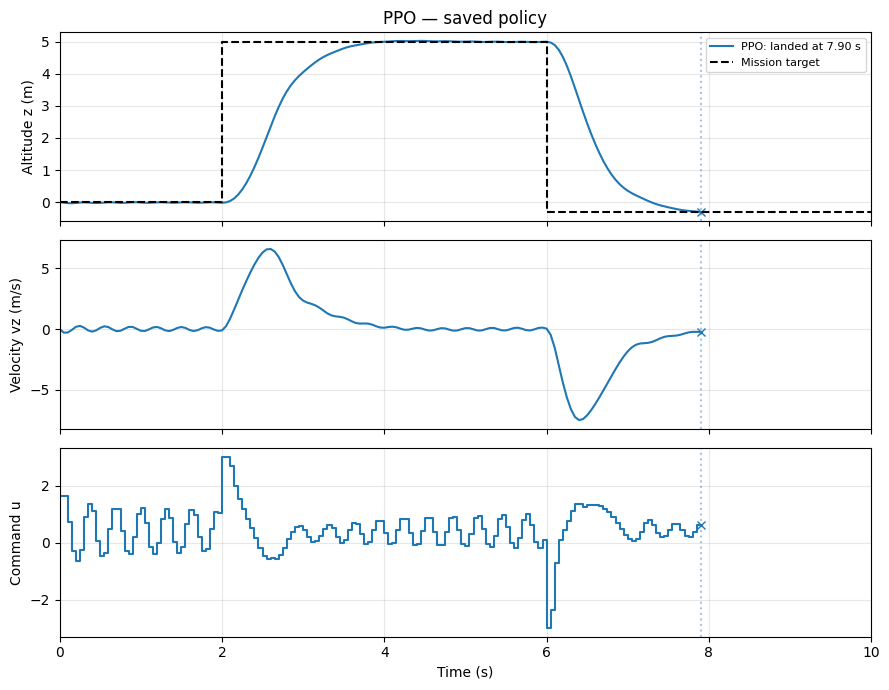

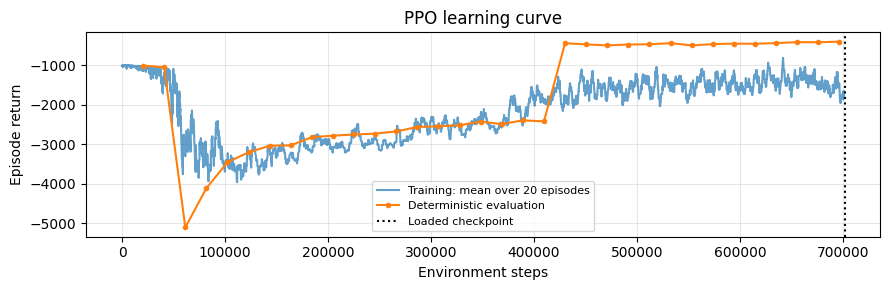

Curriculum agent
PPO: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_fixed_vs_curriculum_20261106_134016/curriculum/ppo_drone_rnn.zip (701,440 training steps)
PPO: landed at 8.25 s | return -427.5 | MAE 0.907 m | peak altitude 5.002 m | final vz -0.133 m/s | RMS delta-u 0.462


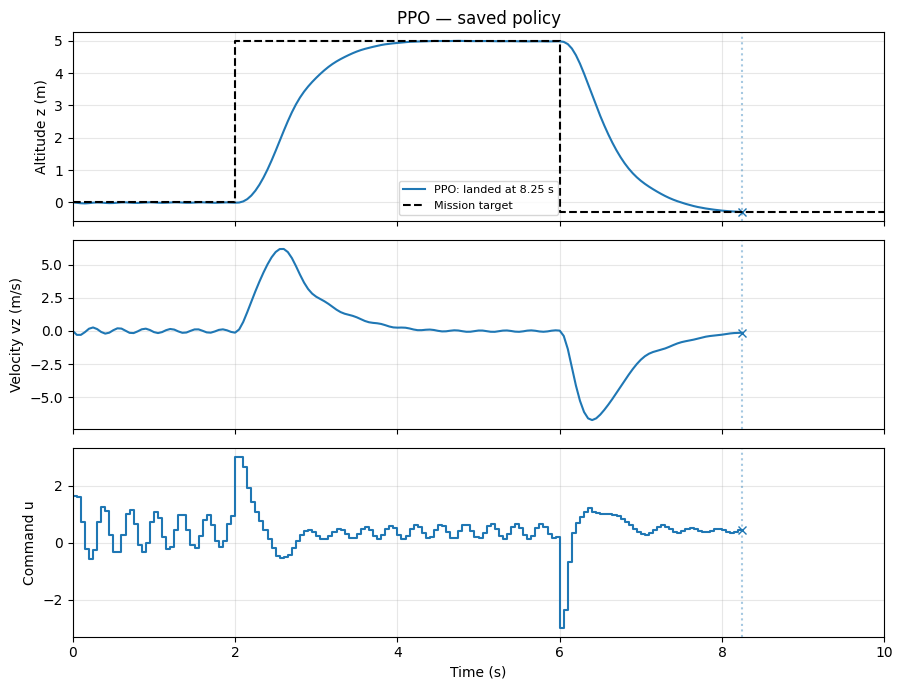

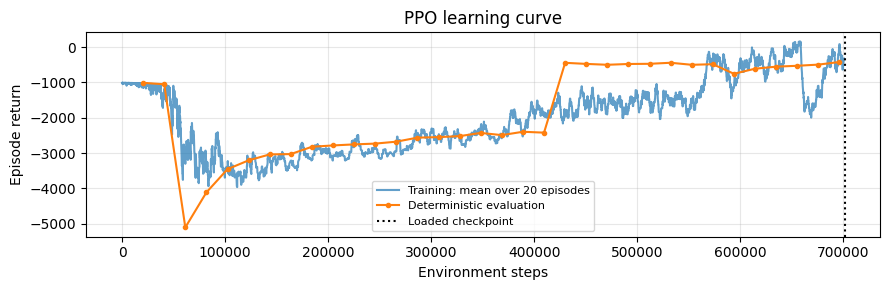

In [9]:
print("Fixed 5 m agent")
show_result("PPO", FIXED_MODEL_PATH, mission_to_test=fixed_5m_mission)
print("Curriculum agent")
show_result("PPO", CURRICULUM_MODEL_PATH, mission_to_test=fixed_5m_mission)
agent = PPO.load(CURRICULUM_MODEL_PATH, device="cpu")
PPO_MODEL_PATH = CURRICULUM_MODEL_PATH


In [10]:
# Export the same final checkpoints used in the comparison.
from policy.export_policy import export_for_matlab
for checkpoint in [FIXED_MODEL_PATH, CURRICULUM_MODEL_PATH]:
    export_agent = PPO.load(checkpoint, device="cpu")
    export_env = DroneEnv(rnn_model=acceleration_rnn, mission=fixed_5m_mission)
    try:
        export_for_matlab(export_agent, export_env, output_dir=checkpoint.parent / "final_matlab")
    finally:
        export_env.close()
LOG_DIR = CURRICULUM_MODEL_PATH.parent / "final_matlab"


Exported /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_fixed_vs_curriculum_20261106_134016/fixed_5m/final_matlab/policy.mat and /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_fixed_vs_curriculum_20261106_134016/fixed_5m/final_matlab/traj_model.mat (158 steps; command error 1.3e-07)
Exported /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_fixed_vs_curriculum_20261106_134016/curriculum/final_matlab/policy.mat and /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_fixed_vs_curriculum_20261106_134016/curriculum/final_matlab/traj_model.mat (165 steps; command error 1.9e-07)


PPO: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_fixed_vs_curriculum_20261106_134016/curriculum/ppo_drone_rnn.zip (701,440 training steps)
PPO: landed at 7.80 s | return 842.6 | MAE 0.110 m | peak altitude 0.497 m | final vz -0.136 m/s | RMS delta-u 0.466


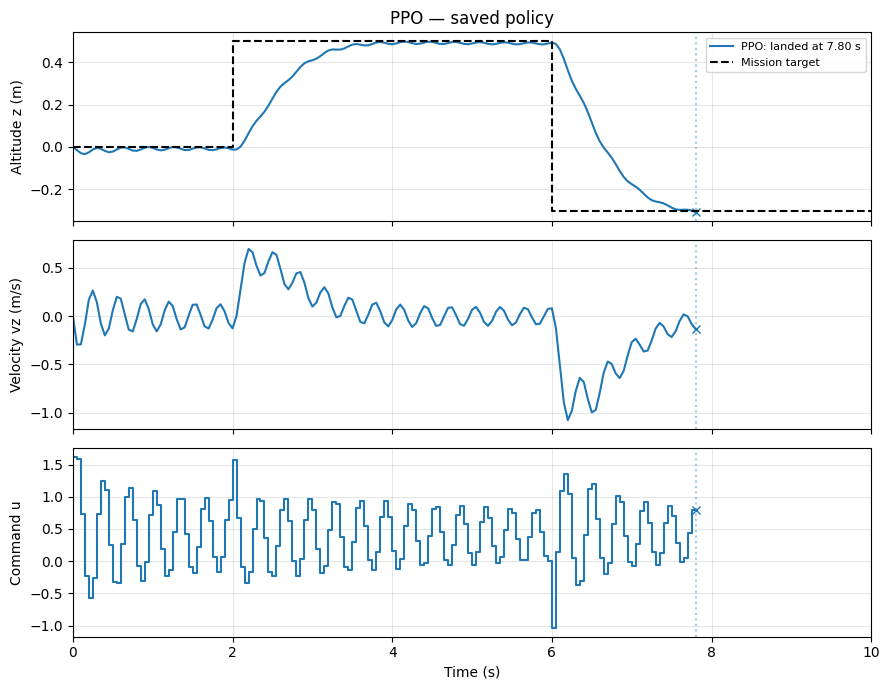

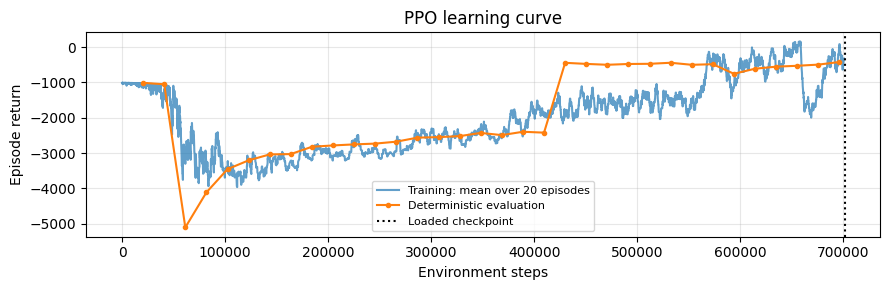

In [11]:
show_result("PPO", PPO_MODEL_PATH, mission_to_test= lambda t: 0.0 if t < 2.0 else (0.5 if t < 6.0 else Z_LAND))

## Check training budgets, settings, and actual exposure

Both policies are frozen before the tests. Their recorded PPO parameters, seed,
environment count, RNN weights/normalization, and final training budgets must match.
The fixed agent saw only a **5 m target**. Curriculum exposure comes from recorded
completed episodes. A height crossed during a climb does not count as a trained target.

Here "seen" refers to the positive hover target. Both agents also share
the 0 m initial hold and -0.3 m landing references.


In [12]:
CHECKPOINTS = {"Fixed 5 m": FIXED_MODEL_PATH, "Curriculum": CURRICULUM_MODEL_PATH}
AGENT_COLORS = {"Fixed 5 m": "tab:blue", "Curriculum": "tab:orange"}
comparison_agents = {name: PPO.load(path, device="cpu") for name, path in CHECKPOINTS.items()}
run_configs = {name: json.loads((path.parent / "ppo_config.json").read_text())
               for name, path in CHECKPOINTS.items()}
fixed_config, curriculum_config = run_configs["Fixed 5 m"], run_configs["Curriculum"]
for key in ["total_timesteps", "seed", "n_envs", "initial_log_std", "ppo"]:
    assert fixed_config[key] == curriculum_config[key], f"Unmatched setting: {key}"
assert fixed_config["metadata"]["dynamics_sha256"] == curriculum_config["metadata"]["dynamics_sha256"]
assert fixed_config["metadata"]["dynamics_sha256"] == dynamics_fingerprint(acceleration_rnn, PARAMS)
assert len({model.num_timesteps for model in comparison_agents.values()}) == 1
for name, model in comparison_agents.items():
    assert model.num_timesteps == run_configs[name]["metadata"]["actual_timesteps"]
    assert model.num_timesteps >= run_configs[name]["total_timesteps"]

COMPARISON_DIR = FIXED_MODEL_PATH.parent.parent / "comparison"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)
training_episodes = pd.read_csv(CURRICULUM_MODEL_PATH.parent / "curriculum_episodes.csv")
curriculum_stages = pd.read_csv(CURRICULUM_MODEL_PATH.parent / "curriculum_stages.csv")
training_heights = {"Fixed 5 m": {5.0}, "Curriculum": set(training_episodes["height_m"])}
training_coverage = training_episodes.groupby("height_m").size().rename("training_episodes").reset_index()
training_coverage["agent"] = "Curriculum"
fixed_coverage = pd.DataFrame({"agent": ["Fixed 5 m"], "height_m": [5.0],
                               "training_episodes": [len(load_results(str(FIXED_MODEL_PATH.parent)))]})
training_coverage = pd.concat([fixed_coverage, training_coverage], ignore_index=True)
display(training_coverage.sort_values(["agent", "height_m"]))
training_coverage.to_csv(COMPARISON_DIR / "training_coverage.csv", index=False)
training_settings = pd.DataFrame([{
    "agent": name, "seed": run_configs[name]["seed"],
    "requested_steps": run_configs[name]["total_timesteps"], "actual_steps": model.num_timesteps,
    "n_envs": run_configs[name]["n_envs"], "training_targets_m": sorted(training_heights[name]),
    "checkpoint": str(CHECKPOINTS[name]),
} for name, model in comparison_agents.items()])
display(training_settings.drop(columns="checkpoint"))
training_settings.to_csv(COMPARISON_DIR / "training_settings.csv", index=False)


,agent,height_m,training_episodes
1,Curriculum,0.5,266
2,Curriculum,1.0,322
3,Curriculum,2.0,131
4,Curriculum,5.0,6971
0,Fixed 5 m,5.0,7695


,agent,seed,requested_steps,actual_steps,n_envs,training_targets_m
0,Fixed 5 m,0,700000,701440,10,[5.0]
1,Curriculum,0,700000,701440,10,"[0.5, 1.0, 2.0, 5.0]"


## Common test missions and evaluation metrics

Both agents face the same **18 target heights × 5 timings = 90 missions each**.
Standard timing is hold 0 m until 2 s, climb/hold until 6 s, then land at -0.3 m
before the existing 10 s deadline. The other four timings test schedule changes.

Common categories make the comparison fair: shared seen target; targets seen only
by curriculum; targets unseen by both inside the curriculum's range; and targets
unseen by both outside that range. Agent-specific seen/unseen labels are also saved,
but those aggregates contain different height sets for the two agents.

The environment is deterministic. Timing cases are distinct missions, not independent
random-seed trials. Standard deviations describe these scenarios; this is one matched
training seed, not an estimate of variation across separately trained agents.

Success uses `info["is_success"]`: reach the altitude tolerance and land softly.
Failures stay in every success-rate denominator. Hover errors cover the final second
before descent and are missing if that phase was incomplete. Touchdown speeds include
crashes. Returns and whole-flight errors accompany outcomes, since early termination
changes their duration.


In [13]:
EVAL_HEIGHTS = [0.1,0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5,
                4.0, 4.5, 5.0]
MISSION_TIMINGS = [("standard", 2.0, 6.0), ("early", 1.5, 5.5),
                   ("late", 2.5, 6.5), ("short_hover", 2.0, 5.5),
                   ("long_hover", 2.0, 6.5)]

def mission_category(height):
    fixed_seen = height in training_heights["Fixed 5 m"]
    curriculum_seen = height in training_heights["Curriculum"]
    if fixed_seen and curriculum_seen:
        return "Shared seen"
    if curriculum_seen:
        return "Curriculum only"
    if fixed_seen:
        return "Fixed only"
    low, high = min(training_heights["Curriculum"]), max(training_heights["Curriculum"])
    return "Unseen both: interpolation" if low < height < high else "Unseen both: extrapolation"

def evaluate_height_mission(model, height, climb_time, land_time):
    def mission(t):
        return 0.0 if t < climb_time else (float(height) if t < land_time else Z_LAND)
    env = DroneEnv(rnn_model=acceleration_rnn, mission=mission)
    obs, info = env.reset(seed=100)
    states, commands, times, rewards = [env.state.copy()], [], [0.0], []
    try:
        while True:
            action, _ = model.predict(obs, deterministic=True)
            obs, reward, terminated, truncated, info = env.step(action)
            states.append(env.state.copy())
            commands.append(float(np.asarray(action).reshape(-1)[0]))
            times.append(env.t)
            rewards.append(float(reward))
            if terminated or truncated:
                break
    finally:
        env.close()
    states, times, commands = np.asarray(states), np.asarray(times), np.asarray(commands)
    targets = np.array([mission(t) for t in times])
    positive_phase = (times >= climb_time) & (times < land_time)
    reached = positive_phase & (np.abs(states[:, 0] - height) <= Z_TRACK_TOLERANCE)
    hover_window = (times >= land_time - 1.0) & (times < land_time)
    completed_hover = times[-1] >= land_time
    hover_error = states[hover_window, 0] - height
    tracking_error = states[1:, 0] - targets[1:]
    success = bool(info["is_success"])
    failure_reason = ("success" if success else "landed without target"
                      if info["outcome"] == "landed" else info["outcome"])
    metrics = {
        "success": success, "target_reached": bool(reached.any()),
        "soft_landed": info["outcome"] == "landed", "outcome": info["outcome"],
        "failure_reason": failure_reason, "return": float(np.sum(rewards)),
        "duration_s": float(times[-1]), "completed_hover": completed_hover,
        "hover_mae_m": float(np.abs(hover_error).mean()) if completed_hover else np.nan,
        "hover_rmse_m": float(np.sqrt(np.mean(hover_error**2))) if completed_hover else np.nan,
        "tracking_mae_m": float(np.abs(tracking_error).mean()),
        "tracking_rmse_m": float(np.sqrt(np.mean(tracking_error**2))),
        "peak_altitude_m": float(states[:, 0].max()),
        "overshoot_m": max(0.0, float(states[:, 0].max()) - height),
        "reach_delay_s": float(times[reached][0] - climb_time) if reached.any() else np.nan,
        "touchdown_speed_m_s": abs(float(states[-1, 1])) if states[-1, 0] <= Z_LAND else np.nan,
        "max_abs_vz_m_s": float(np.abs(states[:, 1]).max()),
        "rms_delta_u": float(np.sqrt(np.mean(np.diff(np.r_[0.0, commands])**2))),
        "mean_command_sq": float(np.mean(commands**2)),
    }
    trajectory = dict(t=times, z=states[:, 0], vz=states[:, 1], az=states[:, 2],
                      target=targets, thrust=np.r_[commands, np.nan], rewards=np.asarray(rewards))
    return metrics, trajectory


In [14]:
comparison_rows, comparison_trajectories = [], {}
for name, model in comparison_agents.items():
    trace_dir = COMPARISON_DIR / ("fixed_5m" if name == "Fixed 5 m" else "curriculum")
    trace_dir.mkdir(parents=True, exist_ok=True)
    for height in EVAL_HEIGHTS:
        for timing, climb_time, land_time in MISSION_TIMINGS:
            metrics, trajectory = evaluate_height_mission(model, height, climb_time, land_time)
            metrics.update(agent=name, height_m=height, timing=timing,
                           climb_time_s=climb_time, land_time_s=land_time,
                           category=mission_category(height),
                           agent_seen=height in training_heights[name])
            comparison_rows.append(metrics)
            comparison_trajectories[(name, height, timing)] = trajectory
            np.savez(trace_dir / f"{height:g}m_{timing}.npz", **trajectory)

comparison_results = pd.DataFrame(comparison_rows)
comparison_results.to_csv(COMPARISON_DIR / "mission_results.csv", index=False)
assert comparison_results.groupby("agent").size().nunique() == 1
assert len(comparison_results) == len(comparison_agents) * len(EVAL_HEIGHTS) * len(MISSION_TIMINGS)
(COMPARISON_DIR / "comparison_config.json").write_text(json.dumps({
    "checkpoints": {name: str(path) for name, path in CHECKPOINTS.items()},
    "policy_steps": {name: int(model.num_timesteps) for name, model in comparison_agents.items()},
    "training_targets": {name: sorted(values) for name, values in training_heights.items()},
    "training_seed": fixed_config["seed"], "n_envs": fixed_config["n_envs"],
    "ppo": fixed_config["ppo"], "dynamics_sha256": fixed_config["metadata"]["dynamics_sha256"],
    "evaluation_heights": EVAL_HEIGHTS, "timings": MISSION_TIMINGS,
    "max_steps": MAX_STEPS, "dt_s": PARAMS.dt,
    "tracking_tolerance_m": Z_TRACK_TOLERANCE, "safe_touchdown_speed_m_s": SAFE_VZ,
    "checkpoint_rule": "Final checkpoint after equal training budget; no test-set selection",
    "deterministic_evaluation": True,
}, indent=2))
print(f"Completed {len(comparison_results)} flights: {len(EVAL_HEIGHTS) * len(MISSION_TIMINGS)} matched missions per agent.")
print("Results:", COMPARISON_DIR)


Completed 130 flights: 65 matched missions per agent.
Results: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_fixed_vs_curriculum_20261106_134016/comparison


## Standard missions, per-height statistics, and failure types

The first table isolates altitude generalization with training timing (2 s / 6 s).
The per-height table summarizes all five schedules. Missing hover errors remain
missing; they are not converted to zero. The full CSVs retain all tracking,
transient, landing, return, and command metrics.


In [15]:
standard_results = comparison_results[comparison_results["timing"] == "standard"]
standard_table = standard_results.pivot(index=["height_m", "category"], columns="agent",
                                         values=["success", "outcome", "hover_mae_m", "touchdown_speed_m_s"])
print("Standard timing: climb at 2 s, descend at 6 s")
display(standard_table.style.format(precision=3))
standard_table.to_csv(COMPARISON_DIR / "standard_missions.csv")

summary_columns = dict(
    missions=("success", "size"), success_pct=("success", lambda x: 100 * x.mean()),
    reached_pct=("target_reached", lambda x: 100 * x.mean()),
    soft_landed_pct=("soft_landed", lambda x: 100 * x.mean()),
    completed_hover_n=("hover_mae_m", "count"),
    hover_mae_mean_m=("hover_mae_m", "mean"), hover_mae_std_m=("hover_mae_m", "std"),
    hover_rmse_mean_m=("hover_rmse_m", "mean"),
    reach_delay_mean_s=("reach_delay_s", "mean"), overshoot_mean_m=("overshoot_m", "mean"),
    touchdown_n=("touchdown_speed_m_s", "count"),
    touchdown_speed_mean_m_s=("touchdown_speed_m_s", "mean"),
    touchdown_speed_std_m_s=("touchdown_speed_m_s", "std"),
    duration_mean_s=("duration_s", "mean"), return_mean=("return", "mean"), return_std=("return", "std"),
    rms_delta_u_mean=("rms_delta_u", "mean"), mean_command_sq=("mean_command_sq", "mean"),
)
per_height_stats = comparison_results.groupby(["height_m", "agent"]).agg(**summary_columns)
display(per_height_stats[["missions", "success_pct", "reached_pct", "completed_hover_n",
                         "hover_mae_mean_m", "hover_mae_std_m", "touchdown_speed_mean_m_s",
                         "reach_delay_mean_s"]].round(3))
per_height_stats.to_csv(COMPARISON_DIR / "per_height_stats.csv")
failure_counts = comparison_results.groupby(["agent", "failure_reason"]).size().unstack(fill_value=0)
print("Outcomes across all missions")
display(failure_counts)
failure_counts.to_csv(COMPARISON_DIR / "failure_counts.csv")


Standard timing: climb at 2 s, descend at 6 s


missions  success_pct  reached_pct  completed_hover_n  \
height_m agent                                                               
0.10     Curriculum         5        100.0        100.0                  5   
         Fixed 5 m          5        100.0        100.0                  5   
0.25     Curriculum         5        100.0        100.0                  5   
         Fixed 5 m          5        100.0        100.0                  5   
0.50     Curriculum         5        100.0        100.0                  5   
         Fixed 5 m          5        100.0        100.0                  5   
0.75     Curriculum         5        100.0        100.0                  5   
         Fixed 5 m          5        100.0        100.0                  5   
1.00     Curriculum         5        100.0        100.0                  5   
         Fixed 5 m          5        100.0        100.0                  5   
1.50     Curriculum         5        100.0        100.0                  5   
         Fixed 5 m          5        100.0        100.0                  5   
2.00     Curriculum         5        100.0        100.0                  5   
         Fixed 5 m          5        100.0        100.0                  5   
2.50     Curriculum         5        100.0        100.0                  5   
         Fixed 5 m          5        100.0        100.0                  5   
3.00     Curriculum         5        100.0        100.0                  5   
         Fixed 5 m          5        100.0        100.0                  5   
3.50     Curriculum         5        100.0        100.0                  5   
         Fixed 5 m          5        100.0        100.0                  5   
4.00     Curriculum         5        100.0        100.0                  5   
         Fixed 5 m          5        100.0        100.0                  5   
4.50     Curriculum         5        100.0        100.0                  5   
         Fixed 5 m          5        100.0        100.0                  5   
5.00     Curriculum         5        100.0        100.0                  5   
         Fixed 5 m          5        100.0        100.0                  5   

                     hover_mae_mean_m  hover_mae_std_m  \
height_m agent                                           
0.10     Curriculum             0.013            0.000   
         Fixed 5 m              0.012            0.000   
0.25     Curriculum             0.012            0.001   
         Fixed 5 m              0.012            0.000   
0.50     Curriculum             0.012            0.001   
         Fixed 5 m              0.012            0.000   
0.75     Curriculum             0.012            0.001   
         Fixed 5 m              0.012            0.001   
1.00     Curriculum             0.011            0.001   
         Fixed 5 m              0.012            0.001   
1.50     Curriculum             0.012            0.001   
         Fixed 5 m              0.013            0.001   
2.00     Curriculum             0.013            0.002   
         Fixed 5 m              0.014            0.002   
2.50     Curriculum             0.012            0.002   
         Fixed 5 m              0.014            0.003   
3.00     Curriculum             0.012            0.003   
         Fixed 5 m              0.013            0.002   
3.50     Curriculum             0.011            0.003   
         Fixed 5 m              0.011            0.002   
4.00     Curriculum             0.010            0.003   
         Fixed 5 m              0.010            0.002   
4.50     Curriculum             0.009            0.003   
         Fixed 5 m              0.010            0.002   
5.00     Curriculum             0.009            0.003   
         Fixed 5 m              0.010            0.002   

                     touchdown_speed_mean_m_s  reach_delay_mean_s  
height_m agent                                                     
0.10     Curriculum                     0.150                0.00  
       

Outcomes across all missions


failure_reason,success
agent,
Curriculum,65
Fixed 5 m,65


## Fair group comparison and paired outcomes

Common-category comparisons use the exact same missions for both agents.
The agent-specific seen/unseen table is supplementary: "seen" means only 5 m
for the fixed agent, while curriculum has multiple seen targets.

Paired wins mean one agent completed a mission and the other failed. Hover-error
differences use only pairs where both completed the hover window. Positive
`curriculum_minus_fixed` means a larger value for curriculum, so negative error
differences favor curriculum. These are descriptive comparisons of this test grid.

Touchdown averages exclude missions that never contacted the platform; their
sample counts are shown. Paired touchdown differences use only flights where
both agents made contact.


In [16]:
common_category_stats = comparison_results.groupby(["category", "agent"]).agg(**summary_columns)
overall_stats = comparison_results.groupby("agent").agg(**summary_columns)
agent_seen_stats = comparison_results.groupby(["agent", "agent_seen"]).agg(**summary_columns)
print("Overall: identical 90-mission grid")
display(overall_stats[["missions", "success_pct", "reached_pct", "hover_mae_mean_m",
                       "touchdown_n", "touchdown_speed_mean_m_s", "return_mean"]].round(3))
print("Common mission categories")
display(common_category_stats[["missions", "success_pct", "reached_pct", "hover_mae_mean_m",
                              "touchdown_n", "touchdown_speed_mean_m_s", "return_mean"]].round(3))
print("Agent-specific seen/unseen labels (different target sets)")
display(agent_seen_stats[["missions", "success_pct", "hover_mae_mean_m"]].round(3))
overall_stats.to_csv(COMPARISON_DIR / "overall_stats.csv")
common_category_stats.to_csv(COMPARISON_DIR / "common_category_stats.csv")
agent_seen_stats.to_csv(COMPARISON_DIR / "agent_seen_unseen_stats.csv")

fixed_cases = comparison_results[comparison_results.agent == "Fixed 5 m"].set_index(["height_m", "timing"])
curriculum_cases = comparison_results[comparison_results.agent == "Curriculum"].set_index(["height_m", "timing"])
assert fixed_cases.index.equals(curriculum_cases.index)
paired_results = pd.DataFrame(index=fixed_cases.index)
paired_results["category"] = fixed_cases["category"]
paired_results["fixed_success"] = fixed_cases["success"]
paired_results["curriculum_success"] = curriculum_cases["success"]
paired_results["paired_outcome"] = np.select([
    paired_results.fixed_success & paired_results.curriculum_success,
    paired_results.fixed_success & ~paired_results.curriculum_success,
    ~paired_results.fixed_success & paired_results.curriculum_success,
], ["Both succeeded", "Only fixed succeeded", "Only curriculum succeeded"], default="Both failed")
for metric in ["hover_mae_m", "reach_delay_s", "touchdown_speed_m_s", "return"]:
    paired_results[f"curriculum_minus_fixed_{metric}"] = curriculum_cases[metric] - fixed_cases[metric]
paired_counts = pd.crosstab(paired_results["category"], paired_results["paired_outcome"]).reindex(
    columns=["Both succeeded", "Only curriculum succeeded", "Only fixed succeeded", "Both failed"], fill_value=0)
print("Paired mission outcomes")
display(paired_counts)
print("Paired metric differences; missing values are excluded")
display(paired_results.filter(like="curriculum_minus_fixed").agg(["count", "mean", "median", "std"]).round(4))
paired_results.to_csv(COMPARISON_DIR / "paired_missions.csv")
paired_counts.to_csv(COMPARISON_DIR / "paired_outcomes.csv")

print("Missions where exactly one agent succeeded")
discordant_cases = paired_results[paired_results.fixed_success != paired_results.curriculum_success]
display(discordant_cases[["category", "fixed_success", "curriculum_success"]])


Overall: identical 90-mission grid


,missions,success_pct,reached_pct,hover_mae_mean_m,touchdown_n,touchdown_speed_mean_m_s,return_mean
agent,,,,,,,
Curriculum,65,100.0,100.0,0.011,65,0.112,414.340
Fixed 5 m,65,100.0,100.0,0.012,65,0.206,411.481


Common mission categories


missions  success_pct  reached_pct  \
category                   agent                                            
Curriculum only            Curriculum        15        100.0        100.0   
                           Fixed 5 m         15        100.0        100.0   
Shared seen                Curriculum         5        100.0        100.0   
                           Fixed 5 m          5        100.0        100.0   
Unseen both: extrapolation Curriculum        10        100.0        100.0   
                           Fixed 5 m         10        100.0        100.0   
Unseen both: interpolation Curriculum        35        100.0        100.0   
                           Fixed 5 m         35        100.0        100.0   

                                       hover_mae_mean_m  touchdown_n  \
category                   agent                                       
Curriculum only            Curriculum             0.012           15   
                           Fixed 5 m              0.013           15   
Shared seen                Curriculum             0.009            5   
                           Fixed 5 m              0.010            5   
Unseen both: extrapolation Curriculum             0.013           10   
                           Fixed 5 m              0.012           10   
Unseen both: interpolation Curriculum             0.011           35   
                           Fixed 5 m              0.012           35   

                                       touchdown_speed_mean_m_s  return_mean  
category                   agent                                              
Curriculum only            Curriculum                     0.101      720.361  
                           Fixed 5 m                      0.198      705.363  
Shared seen                Curriculum                     0.130     -426.954  
                           Fixed 5 m                      0.234     -395.227  
Unseen both: extrapolation Curriculum                     0.138      883.473  
                           Fixed 5 m                      0.162      851.482  
Unseen both: interpolation Curriculum                     0.106      269.335  
                           Fixed 5 m                      0.218      275.061

Agent-specific seen/unseen labels (different target sets)


missions  success_pct  hover_mae_mean_m
agent      agent_seen                                         
Curriculum False             45        100.0             0.011
           True              20        100.0             0.011
Fixed 5 m  False             60        100.0             0.012
           True               5        100.0             0.010

... (2 outputs left out)

Paired metric differences; missing values are excluded


,curriculum_minus_fixed_hover_mae_m,curriculum_minus_fixed_reach_delay_s,curriculum_minus_fixed_touchdown_speed_m_s,curriculum_minus_fixed_return
count,65.0000,65.0000,65.0000,65.0000
mean,-0.0006,0.0900,-0.0941,2.8594
median,-0.0006,0.1000,-0.1023,1.7830
std,0.0008,0.0581,0.0403,23.1359


Missions where exactly one agent succeeded


,,category,fixed_success,curriculum_success
height_m,timing,,,


## Learning curves and curriculum exposure

Training returns reflect different task distributions. The lower evaluation plot
is directly comparable: both runs were evaluated on the same fixed 5 m mission.
The stage plot shows requested curriculum heights, applied at each environment's next reset.


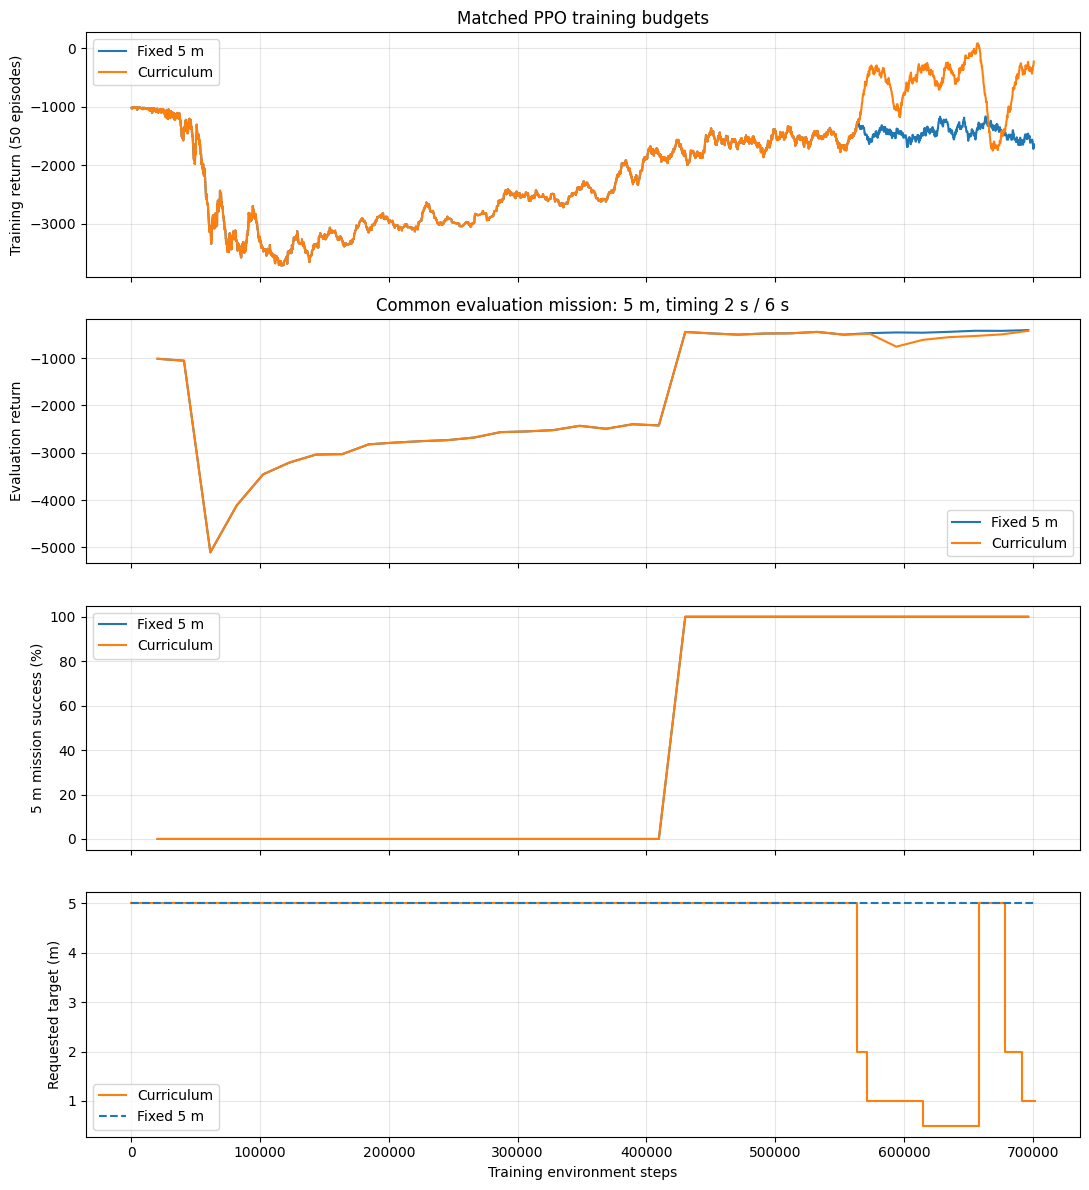

In [17]:
fig, axes = plt.subplots(4, 1, figsize=(11, 12), sharex=True)
for name, checkpoint in CHECKPOINTS.items():
    history = load_results(str(checkpoint.parent))
    steps = history["l"].cumsum().to_numpy()
    returns = history["r"].to_numpy()
    window = min(50, len(returns))
    axes[0].plot(steps[window - 1:], np.convolve(returns, np.ones(window) / window, "valid"),
                 color=AGENT_COLORS[name], label=name)
    with np.load(checkpoint.parent / "evaluations.npz") as evaluations:
        axes[1].plot(evaluations["timesteps"], evaluations["results"].mean(axis=1),
                     color=AGENT_COLORS[name], label=name)
        axes[2].plot(evaluations["timesteps"], 100 * evaluations["successes"].mean(axis=1),
                     color=AGENT_COLORS[name], label=name)
axes[0].set(ylabel="Training return (50 episodes)", title="Matched PPO training budgets")
axes[1].set(ylabel="Evaluation return", title="Common evaluation mission: 5 m, timing 2 s / 6 s")
axes[2].set(ylabel="5 m mission success (%)", ylim=(-5, 105))
end_step = comparison_agents["Curriculum"].num_timesteps
axes[3].step(np.r_[curriculum_stages.steps, end_step],
             np.r_[curriculum_stages.height_m, curriculum_stages.height_m.iloc[-1]],
             where="post", color=AGENT_COLORS["Curriculum"], label="Curriculum")
axes[3].plot([0, end_step], [5, 5], color=AGENT_COLORS["Fixed 5 m"], linestyle="--", label="Fixed 5 m")
axes[3].set(xlabel="Training environment steps", ylabel="Requested target (m)")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(COMPARISON_DIR / "learning_curves.png", dpi=150)
plt.show()


## Performance by target height

Each point summarizes five timing scenarios. Error bars show their standard deviation.
The touchdown panel includes crashes; the dashed line is the existing soft-landing limit.


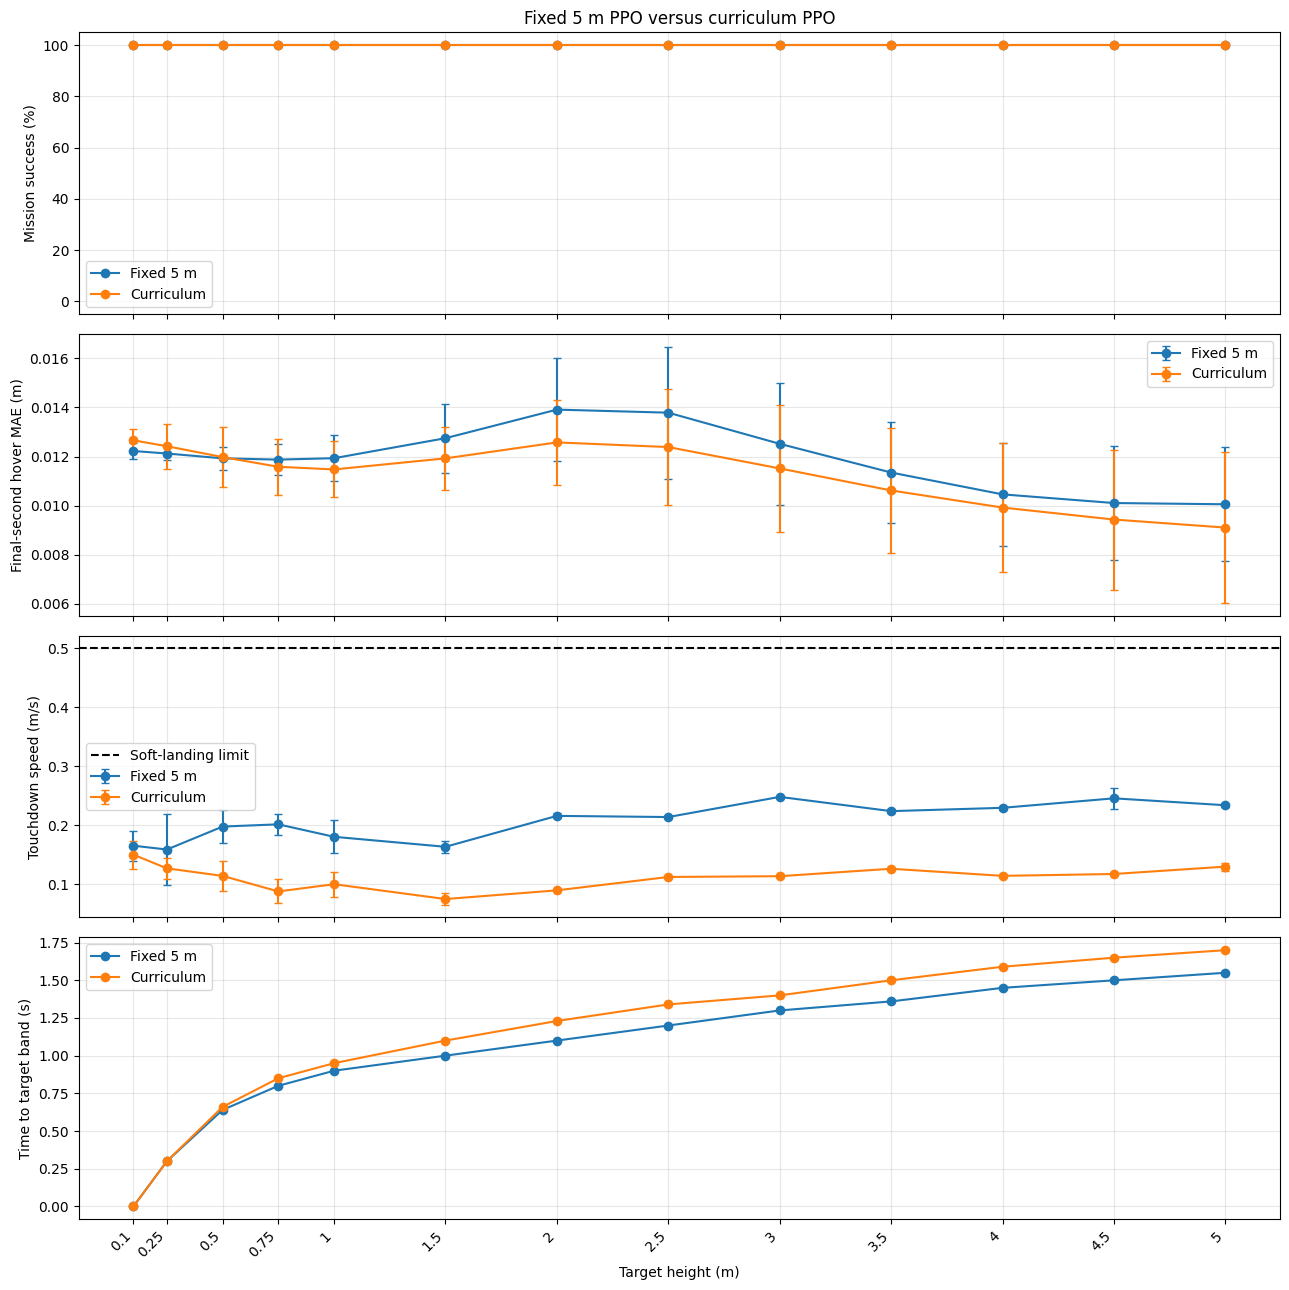

In [18]:
fig, axes = plt.subplots(4, 1, figsize=(13, 13), sharex=True)
for name in CHECKPOINTS:
    data = per_height_stats.xs(name, level="agent").reindex(EVAL_HEIGHTS)
    color = AGENT_COLORS[name]
    axes[0].plot(EVAL_HEIGHTS, data.success_pct, marker="o", color=color, label=name)
    axes[1].errorbar(EVAL_HEIGHTS, data.hover_mae_mean_m, yerr=data.hover_mae_std_m.fillna(0),
                     fmt="o-", capsize=3, color=color, label=name)
    axes[2].errorbar(EVAL_HEIGHTS, data.touchdown_speed_mean_m_s,
                     yerr=data.touchdown_speed_std_m_s.fillna(0), fmt="o-", capsize=3,
                     color=color, label=name)
    axes[3].plot(EVAL_HEIGHTS, data.reach_delay_mean_s, marker="o", color=color, label=name)
axes[0].set(ylabel="Mission success (%)", ylim=(-5, 105), title="Fixed 5 m PPO versus curriculum PPO")
axes[1].set(ylabel="Final-second hover MAE (m)")
axes[2].axhline(SAFE_VZ, color="black", linestyle="--", label="Soft-landing limit")
axes[2].set(ylabel="Touchdown speed (m/s)")
axes[3].set(ylabel="Time to target band (s)", xlabel="Target height (m)")
axes[3].set_xticks(EVAL_HEIGHTS, labels=[f"{h:g}" for h in EVAL_HEIGHTS], rotation=45, ha="right")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
fig.tight_layout()
fig.savefig(COMPARISON_DIR / "performance_by_height.png", dpi=150)
plt.show()


## Standard mission trajectories and landing diagnostics

These overlays use identical references. Each trajectory stops at its own terminal
event. The diagnostics show altitude, velocity, and the actual raw command at
0.25, 5, 7, and 9 m, separating tracking performance from landing behavior.


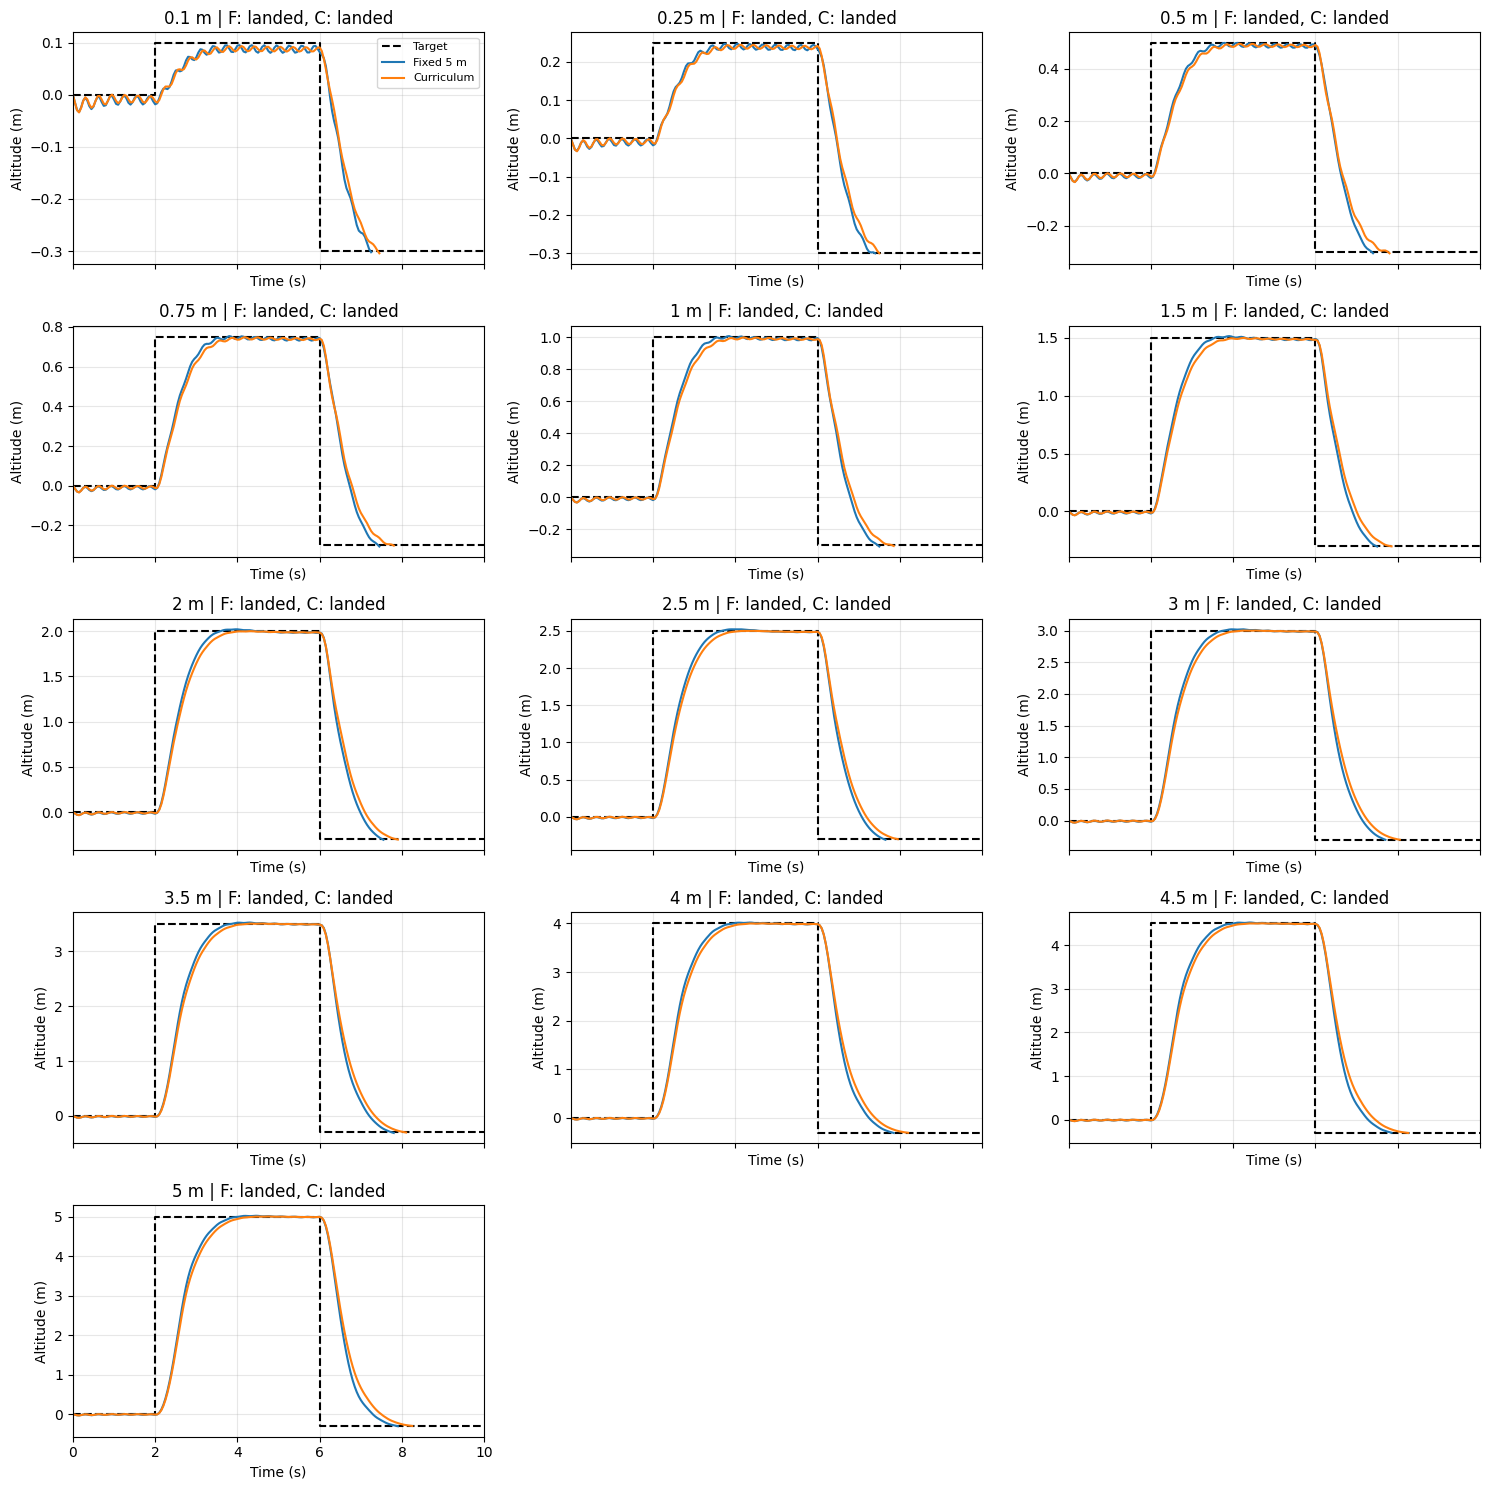

KeyError: ('Fixed 5 m', 7.0, 'standard')

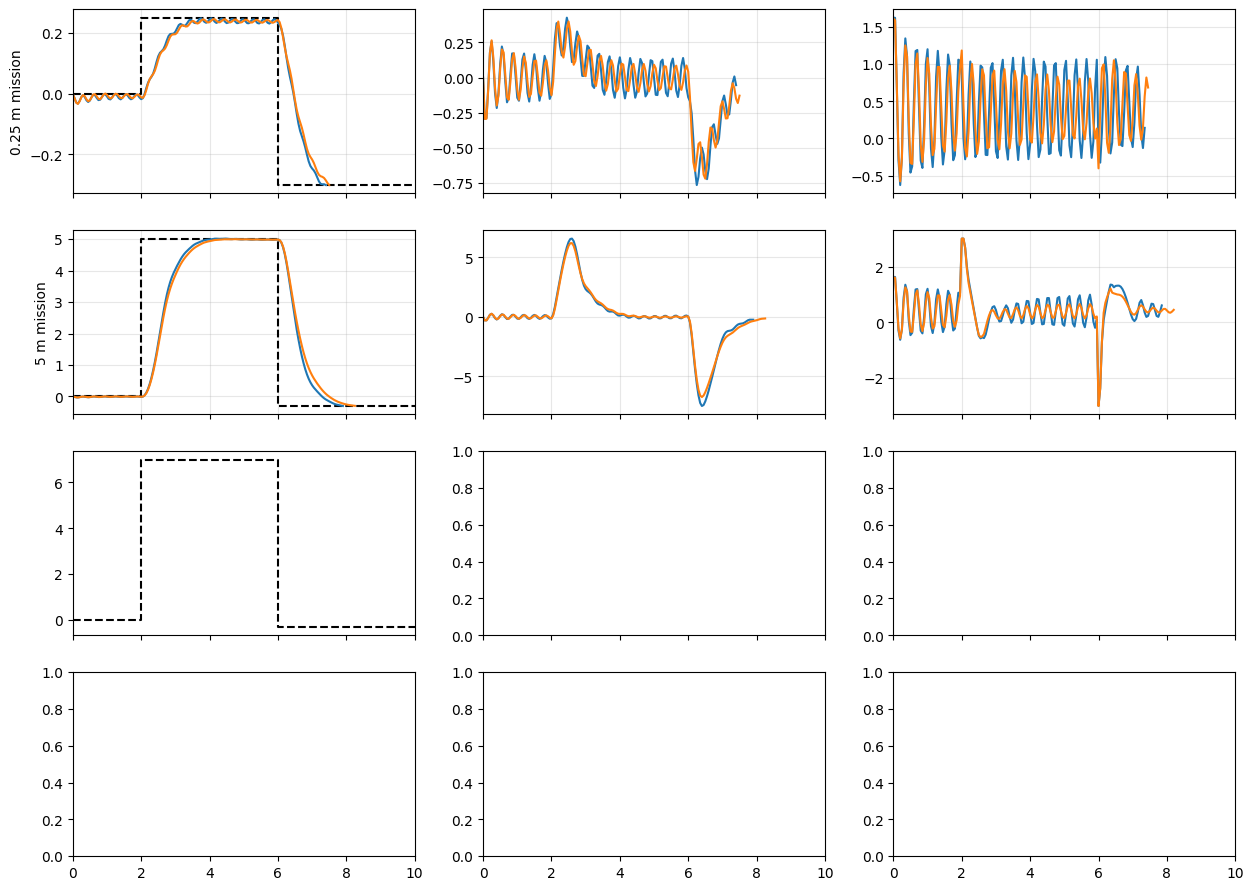

In [19]:
reference_t = np.arange(MAX_STEPS + 1) * PARAMS.dt
fig, axes = plt.subplots(int(np.ceil(len(EVAL_HEIGHTS) / 3)), 3,
                         figsize=(15, 3 * int(np.ceil(len(EVAL_HEIGHTS) / 3))), sharex=True)
for ax, height in zip(axes.flat, EVAL_HEIGHTS):
    reference_z = np.where(reference_t < 2, 0, np.where(reference_t < 6, height, Z_LAND))
    ax.step(reference_t, reference_z, where="post", color="black", linestyle="--", label="Target")
    statuses = []
    for name in CHECKPOINTS:
        trace = comparison_trajectories[(name, height, "standard")]
        ax.plot(trace["t"], trace["z"], color=AGENT_COLORS[name], label=name)
        case = standard_results[(standard_results.agent == name) & (standard_results.height_m == height)].iloc[0]
        statuses.append(f"{'F' if name == 'Fixed 5 m' else 'C'}: {case.outcome}")
    ax.set(title=f"{height:g} m | {', '.join(statuses)}", xlabel="Time (s)", ylabel="Altitude (m)", xlim=(0, reference_t[-1]))
    ax.grid(alpha=0.3)
for ax in list(axes.flat)[len(EVAL_HEIGHTS):]:
    ax.set_visible(False)
axes.flat[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(COMPARISON_DIR / "standard_mission_overlays.png", dpi=150)
plt.show()

diagnostic_heights = [0.25, 5.0, 7.0, 9.0]
fig, axes = plt.subplots(len(diagnostic_heights), 3, figsize=(15, 11), sharex=True)
for row, height in enumerate(diagnostic_heights):
    reference_z = np.where(reference_t < 2, 0, np.where(reference_t < 6, height, Z_LAND))
    axes[row, 0].step(reference_t, reference_z, where="post", color="black", linestyle="--")
    for name in CHECKPOINTS:
        trace = comparison_trajectories[(name, height, "standard")]
        for col, key in enumerate(["z", "vz", "thrust"]):
            axes[row, col].plot(trace["t"], trace[key], color=AGENT_COLORS[name], label=name)
    axes[row, 0].set_ylabel(f"{height:g} m mission")
    for ax in axes[row]:
        ax.grid(alpha=0.3)
        ax.set_xlim(0, reference_t[-1])
for col, title in enumerate(["Altitude z (m)", "Vertical speed vz (m/s)", "Raw thrust command"]):
    axes[0, col].set_title(title)
    axes[-1, col].set_xlabel("Time (s)")
axes[0, 0].legend()
fig.tight_layout()
fig.savefig(COMPARISON_DIR / "landing_diagnostics.png", dpi=150)
plt.show()


## Read the comparison

The summary below is generated from the frozen agents' test results. It reports
paired successes and failures, rather than selecting a winner from training return.
The full case-level data and all summaries are saved beside these plots.


In [ ]:
for name, cases in comparison_results.groupby("agent"):
    standard = cases[cases.timing == "standard"]
    print(f"{name}: {cases.success.sum()}/{len(cases)} full missions passed "
          f"({100 * cases.success.mean():.1f}%); "
          f"standard timing: {standard.success.sum()}/{len(standard)} heights.")
    failed_heights = sorted(cases.loc[~cases.success, "height_m"].unique())
    print("  Heights with at least one failed timing:", failed_heights or "none")
print("Paired outcomes:", paired_results.paired_outcome.value_counts().to_dict())
print("Held-out missions were not used for training, tuning, or checkpoint selection.")
print("This comparison uses one matched training seed; timing cases are deterministic scenarios.")
print("Saved comparison:", COMPARISON_DIR)

fixed_score, curriculum_score = overall_stats.loc["Fixed 5 m"], overall_stats.loc["Curriculum"]
print(f"Curriculum minus fixed success rate: {curriculum_score.success_pct - fixed_score.success_pct:+.2f} percentage points.")
print(f"Mean final-second hover MAE: fixed {1000 * fixed_score.hover_mae_mean_m:.2f} mm; "
      f"curriculum {1000 * curriculum_score.hover_mae_mean_m:.2f} mm.")
contact_differences = paired_results["curriculum_minus_fixed_touchdown_speed_m_s"].dropna()
print(f"On {len(contact_differences)} pairs with actual touchdown, curriculum minus fixed "
      f"touchdown speed averages {contact_differences.mean():+.3f} m/s (positive means faster contact).")
print("Both agents failed at heights:", sorted(paired_results.loc[
    paired_results.paired_outcome == "Both failed"].reset_index().height_m.unique().tolist()))


Curriculum: 70/90 full missions passed (77.8%); standard timing: 14/18 heights.
  Heights with at least one failed timing: [np.float64(6.5), np.float64(7.0), np.float64(8.0), np.float64(9.0)]
Fixed 5 m: 66/90 full missions passed (73.3%); standard timing: 13/18 heights.
  Heights with at least one failed timing: [np.float64(0.25), np.float64(6.5), np.float64(7.0), np.float64(8.0), np.float64(9.0)]
Paired outcomes: {'Both succeeded': 66, 'Both failed': 20, 'Only curriculum succeeded': 4}
Held-out missions were not used for training, tuning, or checkpoint selection.
This comparison uses one matched training seed; timing cases are deterministic scenarios.
Saved comparison: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_fixed_vs_curriculum_20261106_130314/comparison
Curriculum minus fixed success rate: +4.44 percentage points.
Mean final-second hover MAE: fixed 14.88 mm; curriculum 2.57 mm.
On 86 pairs with actual touchdown, curriculum minus fixed touchdown speed averag

## Changing mission

In [ ]:
def test_mission(t):
    """Hold 0 m until 2 s, hover at 2 m until 5 s, then land."""
    return 0.0 if t < 2.0 else (9.0 if t < 5.0 else Z_LAND)


PPO: /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_fixed_vs_curriculum_20261106_130314/curriculum/ppo_drone_rnn.zip (1,500,160 training steps)
PPO: crashed at 6.10 s | return -3877.4 | MAE 2.171 m | peak altitude 9.275 m | final vz -6.192 m/s | RMS delta-u 0.517


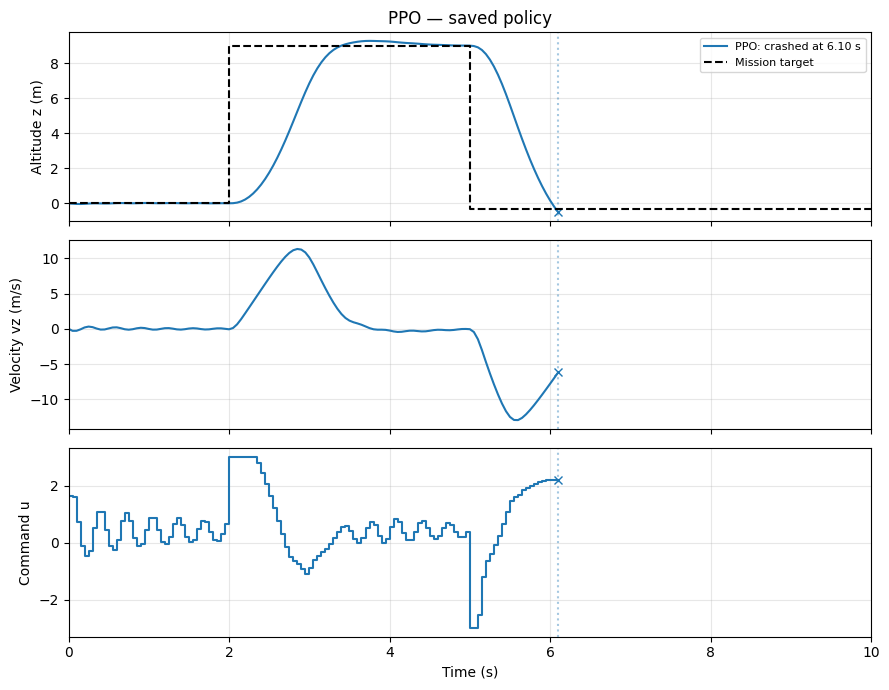

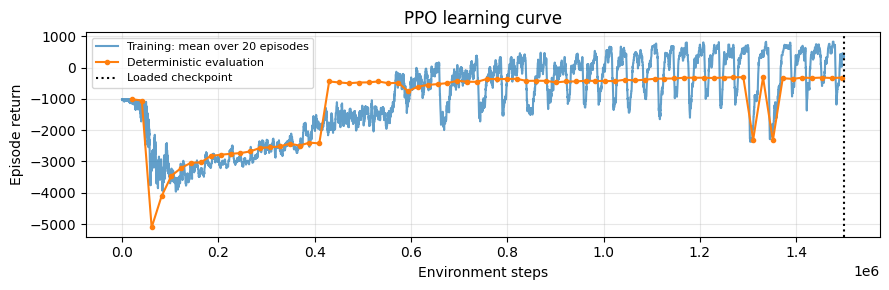

In [ ]:
show_result("PPO", PPO_MODEL_PATH, mission_to_test=test_mission)

## DQN — optional training

Skipped when `SKIP_DQN=True` in Setup.

Use 61 commands evenly spaced across `[-3.0, 3.0]` (0.1 increments), covering
its full environment action range for the selected mission. Rerun this training
cell to learn with the wider command range; existing checkpoints retain their
original saved `commands.npy`. The Results cell reports peak altitude so you can
check whether the trained policy reaches its target.

Training settings and the command grid are loaded from `src/policy/config/dqn.json`.
The successful DQN settings use `n_steps=3`, `tau=0.1`, and `train_freq=5`.
With `gradient_steps=-1`, 50 transitions are followed by 50 updates with 10 environments.

Sources: [DQN parameters](https://stable-baselines3.readthedocs.io/en/master/modules/dqn.html#parameters),
[multi-environment update guidance](https://stable-baselines3.readthedocs.io/en/master/guide/examples.html#multiprocessing-with-off-policy-algorithms).


In [ ]:
if SKIP_DQN:
    print("DQN skipped (SKIP_DQN=True).")
else:
    def make_dqn_env():
        env = DiscreteDroneActions(DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission))
        return env

    dqn_env = make_vec_env(make_dqn_env, n_envs=DQN_CONFIG["n_envs"], seed=DQN_CONFIG["seed"], monitor_dir=str(DQN_DIR))
    dqn_eval = make_vec_env(make_dqn_env, n_envs=1, seed=100)
    dqn_callback = EvalCallback(
        dqn_eval, best_model_save_path=str(DQN_DIR), log_path=str(DQN_DIR),
        eval_freq=max(1, DQN_CONFIG["eval_freq"] // DQN_CONFIG["n_envs"]), n_eval_episodes=1, deterministic=True, verbose=0,
    )
    dqn_agent = DQN("MlpPolicy", dqn_env, seed=DQN_CONFIG["seed"], device="cpu", verbose=0, **DQN_PARAMS)
    start = time.perf_counter()
    dqn_agent.learn(total_timesteps=DQN_STEPS, callback=dqn_callback)
    dqn_agent.save(DQN_DIR / "dqn_drone_rnn")
    np.save(DQN_DIR / "commands.npy", DQN_COMMANDS)
    DQN_MODEL_PATH = DQN_DIR / "best_model.zip"
    dqn_env.close()
    dqn_eval.close()
    print(f"DQN: {dqn_agent.num_timesteps:,} steps in {time.perf_counter() - start:.1f} s; {DQN_MODEL_PATH}")


DQN skipped (SKIP_DQN=True).


## DQN — Results

Skipped when `SKIP_DQN=True` in Setup.

Loads only DQN and its saved `commands.npy`; PPO and SAC do not need to run.


In [ ]:
if SKIP_DQN:
    print("DQN skipped (SKIP_DQN=True).")
else:
    show_result("DQN", DQN_MODEL_PATH)


DQN skipped (SKIP_DQN=True).


## SAC — optional training

Skipped when `SKIP_SAC=True` in Setup.

Training uses `train_off_policy` from `policy.training`, just like `main_z.py`.
Settings and the starting checkpoint come from `src/policy/config/sac.json`.
The altitude baseline is `20261105_202000_ztol02/training/best_model.zip` at
327,680 steps. The 500,000-step target includes those existing steps.
The old zip has no replay buffer: training collects 2,000 fresh warmup
transitions before updates. The starting policy is evaluated and saved before
training, and remains selected unless a later evaluation improves its return.
Set `initial_checkpoint` to `null` in the config to train altitude SAC from scratch.

SAC uses the environment's full continuous action space and the fixed mission.
`curriculum_difficulty` optionally enables the altitude curriculum; curriculum
runs select the final checkpoint. TensorBoard logs and a resolved config are
saved under `SAC_DIR`.


In [ ]:
if SKIP_SAC:
    print("SAC skipped (SKIP_SAC=True).")
else:
    sac_curriculum = (
        CurriculumCallback(difficulty=SAC_CONFIG["curriculum_difficulty"], verbose=1)
        if SAC_CONFIG["curriculum_difficulty"] is not None else None
    )
    start = time.perf_counter()
    sac_agent, SAC_MODEL_PATH = train_off_policy(
        "sac", acceleration_rnn, ref_mission, SAC_DIR,
        config_path=PPO_CONFIG_PATH.with_name("sac.json"),
        total_timesteps=SAC_STEPS, seed=SAC_CONFIG["seed"], n_envs=SAC_CONFIG["n_envs"],
        env_class=DroneEnv, curriculum=sac_curriculum,
        **SAC_PARAMS,
    )
    print(f"SAC: selected {sac_agent.num_timesteps:,}-step checkpoint in {time.perf_counter() - start:.1f} s; {SAC_MODEL_PATH}")


SAC skipped (SKIP_SAC=True).


## SAC — Results

Skipped when `SKIP_SAC=True` in Setup.

Loads only SAC; PPO and DQN do not need to run.

For altitude, Setup selects the verified SAC policy from the shared config.
Running the training cell first selects that run's best checkpoint instead.


In [ ]:
if SKIP_SAC:
    print("SAC skipped (SKIP_SAC=True).")
else:
    show_result("SAC", SAC_MODEL_PATH)


SAC skipped (SKIP_SAC=True).


## Export a PPO trajectory

Exports `trajectory_az.csv` into this run's PPO directory using the same selected
mission. MATLAB policy export above also includes that mission's reference samples.


In [ ]:

# 1. Déroulement d'un épisode avec la politique entraînée
eval_env = DroneEnv(rnn_model=acceleration_rnn, mission=ref_mission)
obs, info = eval_env.reset(seed=0)

az_list = [float(eval_env.unwrapped.state[2])]

terminated = False
truncated = False

while not (terminated or truncated):
    action, _ = agent.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = eval_env.step(action)
    az_list.append(float(eval_env.unwrapped.state[2]))

eval_env.close()

# 2. Export sur une seule ligne (chaque case = une valeur de az)
LOG_DIR.mkdir(parents=True, exist_ok=True)
output_path = LOG_DIR / "trajectory_az.csv"
np.savetxt(output_path, [az_list], delimiter=",", fmt="%.6f")

print(f"Trajectoire az exportée ({len(az_list)} valeurs sur 1 ligne) : {output_path}")

Trajectoire az exportée (150 valeurs sur 1 ligne) : /home/rayan768/CS/drone/EI-DATA-DRIVEN-CONTROL/results/policy/rl_z_fixed_vs_curriculum_20261106_130314/curriculum/final_matlab/trajectory_az.csv
